# Sub-etapa 1.4 (complemento) · Respuesta a la revisión del docente guía (Ángel Custodio)

Este notebook responde a los puntos de la revisión del 1 de noviembre de 2026 que requieren análisis nuevos. **No modifica** los notebooks 03, 04 y 05 ni sus resultados: los lee y agrega lo que faltaba.

| Sección | Punto de la revisión | Qué se hace |
|---|---|---|
| 2 | Repositorio, punto 1 | Se escribe `requirements.txt` con las versiones exactas instaladas |
| 3 | Repositorio, punto 3 | Se revisa qué mide la columna "6 Months Fall" y, si corresponde, se evalúa la predicción de caídas futuras |
| 4 | Repositorio, punto 4 · 1.4, punto 7 | Referencia "solo velocidad" y relación entre frecuencia dominante y velocidad |
| 5 | 1.3, punto 5 | Frecuencia dominante, velocidad y TUG comparados en las mismas personas |
| 6 | 1.4, puntos 1, 2 y 5 | El modelo elegido contra el azar y contra el TUG |
| 7 | 1.4, puntos 4 y 6 | Umbral en Hz, umbral elegido sin mirar la prueba, matriz de confusión y calibración |

**Productos:** `requirements.txt`, `resultados/revision_*.csv`, `figuras/revision_*.png`.

**Antes de ejecutarlo:** los notebooks 01, 03 (`DATOS = "laboratorio"`) y 05 deben estar ejecutados.

## Plan de análisis (escrito antes de ejecutar)

Para que estas decisiones queden con fecha anterior a los resultados, **este notebook se sube a GitHub sin ejecutar** (commit "05b: plan de análisis") y recién después se ejecuta y se sube con resultados (segundo commit). Así lo sugirió la revisión.

1. **"6 Months Fall".** Antes de usarla, se cruza con el grupo (CO / FL) y con las caídas del año anterior. Weiss et al. (2013) registraron dos cosas distintas: las caídas de los **6 meses anteriores** (retrospectivo; media 0,15 en controles y 2,56 en quienes caen) y un **seguimiento de 6 meses posterior** con calendarios mensuales (prospectivo; 12 personas con 2 o más caídas). La regla para interpretarla:
   * Si casi todas las personas con caídas en esa columna son FL y su número coincide con las caídas pasadas, se trata como **retrospectiva** y no se usa como etiqueta nueva.
   * Si las caídas aparecen también en controles, o el número con 2 o más caídas se acerca a 12, se trata como **posiblemente prospectiva**. Se evalúa, pero la confirmación final depende de la documentación de LTMM.
   * Etiqueta prospectiva principal: **al menos 1 caída** en la columna. Etiqueta secundaria: **2 o más caídas** (la definición de Weiss).
   * Modelos (todos regresión logística de una variable, mismas particiones 5 × 10): frecuencia dominante, velocidad, TUG y caídas del año anterior. Esta última es la referencia clínica natural para predecir caídas futuras.
2. **Velocidad.** Con la etiqueta de siempre y **las mismas 50 particiones del notebook 03**: "solo velocidad" y "velocidad + frecuencia dominante" (regresión logística). Se informa la correlación de Spearman entre ambas variables.
3. **Mismas personas.** Frecuencia dominante, velocidad y TUG se comparan solo con las personas que tienen los tres datos, sin completar valores faltantes.
4. **Contra el azar y contra el TUG.** El modelo seleccionado ("1 variable de cámara elegida en cada partición") y la frecuencia dominante fija se comparan con AUC = 0,5 y con "Solo TUG", con la prueba t corregida y Holm sobre las cuatro comparaciones.
5. **Umbral.** Se expresa en Hz y se estima su desempeño con el umbral elegido **solo con las personas de entrenamiento** de cada partición. Se informan matriz de confusión, puntaje de Brier y curva de calibración.

## 1. Configuración

In [1]:
import json
import platform
import subprocess
import warnings
from datetime import datetime
from importlib import metadata
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.base import clone
from sklearn.calibration import calibration_curve
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, brier_score_loss, confusion_matrix, f1_score, recall_score,
                             roc_auc_score, roc_curve)
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=UserWarning)
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESADOS = RAIZ / "datos" / "procesados"
MODELOS = RAIZ / "modelos"
RESULTADOS = RAIZ / "resultados"
FIGURAS = RAIZ / "figuras"
for carpeta in (RESULTADOS, FIGURAS):
    carpeta.mkdir(parents=True, exist_ok=True)

SEMILLA = 42
N_PARTICIONES = 5
N_REPETICIONES = 10
FRACCION = 1 / (N_PARTICIONES - 1)
SENSIBILIDAD_OBJETIVO = 0.80
ALFA = 0.05
METRICAS = ["exactitud", "sensibilidad", "especificidad", "f1", "auc"]
VARIABLES_CAMARA = ["cadencia_pasos_min", "tiempo_paso_s", "cv_tiempo_paso_pct", "tiempo_zancada_s",
                    "cv_tiempo_zancada_pct", "regularidad_paso", "regularidad_zancada", "simetria",
                    "frec_dominante_hz"]
np.random.seed(SEMILLA)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

# Registro de cuándo y con qué versión del repositorio se ejecutó
try:
    commit = subprocess.run(["git", "rev-parse", "--short", "HEAD"], cwd=RAIZ, capture_output=True,
                            text=True).stdout.strip() or "sin git"
except Exception:
    commit = "sin git"
print(f"Ejecutado: {datetime.now():%Y-%m-%d %H:%M} | commit {commit} | Python {platform.python_version()}")

Ejecutado: 2026-11-03 05:52 | commit sin git | Python 3.14.6


## 2. Versiones exactas (`requirements.txt`)

La revisión pidió fijar las versiones. En vez de escribirlas a mano, esta celda lee las que están instaladas en el computador donde se obtuvieron los resultados y las escribe en `requirements.txt`. XGBoost ya usa un solo hilo (`n_jobs=1` en el notebook 03); la pequeña diferencia que encontró la revisión (AUC 0,644 frente a 0,636) se explica por la versión de XGBoost, y queda resuelta al fijarla.

In [2]:
PAQUETES = ["numpy", "pandas", "scipy", "scikit-learn", "xgboost", "torch", "matplotlib", "wfdb",
            "joblib", "openpyxl", "nbformat", "notebook", "ipykernel"]
lineas, faltan = [], []
for p in PAQUETES:
    try:
        lineas.append(f"{p}=={metadata.version(p)}")
    except metadata.PackageNotFoundError:
        faltan.append(p)
texto = (f"# Versiones con que se obtuvieron los resultados (Python {platform.python_version()})\n"
         f"# Generado por notebooks/05b_Respuesta_revision.ipynb el {datetime.now():%Y-%m-%d}\n" + "\n".join(lineas) + "\n")
(RAIZ / "requirements.txt").write_text(texto, encoding="utf-8")
print(texto)
if faltan:
    print("No instalados (se omiten):", ", ".join(faltan))

# Versiones con que se obtuvieron los resultados (Python 3.14.6)
# Generado por notebooks/05b_Respuesta_revision.ipynb el 2026-11-03
numpy==2.4.6
pandas==3.0.3
scipy==1.18.0
scikit-learn==1.9.0
xgboost==3.4.1
torch==2.14.1
matplotlib==3.11.0
wfdb==4.3.1
joblib==1.5.3
openpyxl==3.1.5
nbformat==5.10.4
notebook==7.5.7
ipykernel==6.31.0



## 3. Funciones (las mismas del notebook 05)

In [3]:
def prueba_t_corregida(a, b):
    # Dos modelos evaluados en las mismas pruebas. Si b es un número (p. ej. 0,5), compara contra ese valor
    d = np.asarray(a, dtype=float) - (np.asarray(b, dtype=float) if np.ndim(b) else float(b))
    J, var = len(d), np.var(d, ddof=1)
    if var == 0:
        return d.mean(), 1.0 if d.mean() == 0 else 0.0
    t = d.mean() / np.sqrt((1 / J + FRACCION) * var)
    return d.mean(), 2 * stats.t.sf(abs(t), df=J - 1)


def intervalo(x):
    x = np.asarray(x, dtype=float)
    J = len(x)
    e = stats.t.ppf(0.975, J - 1) * np.sqrt((1 / J + FRACCION) * np.var(x, ddof=1))
    return x.mean() - e, x.mean() + e


def holm(p):
    p = np.asarray(p, dtype=float)
    orden = np.argsort(p)
    ajustado, acumulado = np.empty_like(p), 0.0
    for k, i in enumerate(orden):
        acumulado = max(acumulado, min(1.0, (len(p) - k) * p[i]))
        ajustado[i] = acumulado
    return ajustado


def metricas(y, prob, umbral=0.5):
    pred = (prob >= umbral).astype(int)
    return {"exactitud": accuracy_score(y, pred), "sensibilidad": recall_score(y, pred, zero_division=0),
            "especificidad": recall_score(y, pred, pos_label=0, zero_division=0),
            "f1": f1_score(y, pred, zero_division=0), "auc": roc_auc_score(y, prob)}


def logistica(k=None):
    pasos = [SimpleImputer(strategy="median"), StandardScaler()]
    if k is not None:
        pasos.append(SelectKBest(f_classif, k=k))
    return make_pipeline(*pasos, LogisticRegression(max_iter=1000))


def evaluar(nombre, modelo, X, y):
    # Validación cruzada 5 x 10 con la misma semilla que los notebooks 03 y 05
    cv = RepeatedStratifiedKFold(n_splits=N_PARTICIONES, n_repeats=N_REPETICIONES, random_state=SEMILLA)
    filas = []
    for j, (ent, pru) in enumerate(cv.split(X, y), start=1):
        m = clone(modelo).fit(X.iloc[ent], y[ent])
        filas.append({"modelo": nombre, "particion": j, **metricas(y[pru], m.predict_proba(X.iloc[pru])[:, 1])})
    return pd.DataFrame(filas)


def resumen(tabla):
    filas = []
    for modelo, g in tabla.groupby("modelo", sort=False):
        a, b = intervalo(g["auc"])
        filas.append({"modelo": modelo, "pruebas": len(g), "auc": round(g["auc"].mean(), 3),
                      "auc_ic95": f"[{a:.2f}; {b:.2f}]",
                      **{m: round(g[m].mean(), 3) for m in METRICAS if m != "auc"}})
    return pd.DataFrame(filas)


def buscar_columna(tabla, *claves):
    # Busca una columna de la planilla clínica sin depender de mayúsculas ni espacios
    norm = {c: str(c).lower().replace(" ", "").replace("_", "") for c in tabla.columns}
    for c, n in norm.items():
        if all(k in n for k in claves):
            return c
    return None

## 4. Datos

Se usa la misma tabla y el mismo orden de personas que el notebook 03 (`labwalks_modelo.csv`), y se le agregan las columnas de la planilla clínica desde `labwalks_variables.csv`.

In [4]:
lab = pd.read_csv(PROCESADOS / "labwalks_modelo.csv")
completo = pd.read_csv(PROCESADOS / "labwalks_variables.csv")
completo["clave"] = completo["registro"].str[:5].str.lower()
lab["clave"] = lab["registro"].str[:5].str.lower()

COL_6M = buscar_columna(completo, "6month")
COL_VEL = buscar_columna(completo, "velocity")
COL_TUG = next((c for c in completo.columns if str(c).strip().upper() == "TUG"), None)
COL_ANO = buscar_columna(completo, "yearfall")
print("Columnas encontradas en la planilla clínica:")
for nombre, c in [("6 meses", COL_6M), ("velocidad", COL_VEL), ("TUG", COL_TUG), ("caídas año anterior", COL_ANO)]:
    print(f"  {nombre:22s} -> {c!r}")

extra = completo[["clave", "frec_dominante_hz"] + [c for c in (COL_6M, COL_VEL, COL_TUG, COL_ANO) if c]]
extra = extra.rename(columns={COL_6M: "caidas_6m", COL_VEL: "velocidad", COL_TUG: "tug", COL_ANO: "caidas_ano"})
d = lab[["registro", "clave", "grupo", "cae"]].merge(extra, on="clave", how="left")
for c in ("caidas_6m", "velocidad", "tug", "caidas_ano"):
    if c in d:
        d[c] = pd.to_numeric(d[c], errors="coerce")
assert len(d) == len(lab) and (d["registro"] == lab["registro"]).all()
y = d["cae"].astype(int).to_numpy()
print(f"\n{len(d)} personas ({(y == 1).sum()} caen, {(y == 0).sum()} no caen)")
d.drop(columns="clave").describe().round(2)

Columnas encontradas en la planilla clínica:
  6 meses                -> '6 Months Fall'
  velocidad              -> 'base(velocity)'
  TUG                    -> 'TUG'
  caídas año anterior    -> 'Year Fall'

72 personas (34 caen, 38 no caen)


,cae,frec_dominante_hz,caidas_6m,velocidad,tug,caidas_ano
count,72.00,72.00,66.00,68.00,68.00,67.00
mean,0.47,1.87,1.33,1.11,11.23,2.03
std,0.50,0.17,2.03,0.27,3.76,2.76
min,0.00,1.29,0.00,0.30,6.24,0.00
25%,0.00,1.77,0.00,0.95,8.63,0.00
50%,0.00,1.87,0.00,1.12,10.80,1.00
75%,1.00,1.95,2.00,1.24,12.45,3.00
max,1.00,2.37,10.00,1.71,30.25,10.00


## 5. ¿Qué mide la columna "6 Months Fall"?

Se aplica la regla escrita en el plan. La tabla cruza el número de caídas de esa columna con el grupo.

In [5]:
ES_PROSPECTIVA = False
if "caidas_6m" not in d:
    print("No se encontró la columna de 6 meses en la planilla; se omite esta sección.")
else:
    con_dato = d[d["caidas_6m"].notna()]
    print(f"Personas con dato: {len(con_dato)} de {len(d)}\n")
    con_dato = con_dato.assign(grupo_etiqueta=np.where(con_dato["cae"] == 1, "cae (FL)", "no cae (CO)"))
    cruce = pd.crosstab(con_dato["caidas_6m"].clip(upper=3).map({0: "0", 1: "1", 2: "2", 3: "3 o más"}),
                        con_dato["grupo_etiqueta"], margins=True, margins_name="Total")
    print("Caídas en la columna '6 Months Fall' según grupo:")
    print(cruce.to_string(), "\n")
    al_menos_1 = con_dato["caidas_6m"] >= 1
    dos_o_mas = int((con_dato["caidas_6m"] >= 2).sum())
    fl_entre_caidas = (con_dato.loc[al_menos_1, "cae"] == 1).mean()
    co_con_caidas = int(((con_dato["cae"] == 0) & al_menos_1).sum())
    print(f"Personas con al menos 1 caída: {int(al_menos_1.sum())} ({fl_entre_caidas:.0%} son FL)")
    print(f"Controles (CO) con al menos 1 caída: {co_con_caidas}")
    print(f"Personas con 2 o más caídas: {dos_o_mas} (en el seguimiento de Weiss et al. fueron 12)")
    if "caidas_ano" in d:
        rho = stats.spearmanr(con_dato["caidas_6m"], con_dato["caidas_ano"], nan_policy="omit")[0]
        print(f"Correlación de Spearman con las caídas del año anterior: ρ = {rho:.2f}")
        print("Medias por grupo:")
        print(con_dato.groupby("grupo_etiqueta")[["caidas_6m", "caidas_ano"]].mean().round(2).to_string())

    # Regla del plan
    parece_retro = fl_entre_caidas >= 0.9 and co_con_caidas <= 2 and abs(dos_o_mas - 12) > 6
    ES_PROSPECTIVA = not parece_retro
    print("\nConclusión según la regla del plan:",
          "POSIBLEMENTE PROSPECTIVA (confirmar con la documentación de LTMM)" if ES_PROSPECTIVA else
          "PARECE RETROSPECTIVA (caídas de los 6 meses anteriores): no se usa como etiqueta nueva")

Personas con dato: 66 de 72

Caídas en la columna '6 Months Fall' según grupo:
grupo_etiqueta  cae (FL)  no cae (CO)  Total
caidas_6m                                   
0                      3           32     35
1                      4            5      9
2                     10            0     10
3 o más               12            0     12
Total                 29           37     66 

Personas con al menos 1 caída: 31 (84% son FL)
Controles (CO) con al menos 1 caída: 5
Personas con 2 o más caídas: 22 (en el seguimiento de Weiss et al. fueron 12)
Correlación de Spearman con las caídas del año anterior: ρ = 0.93
Medias por grupo:
                caidas_6m  caidas_ano
grupo_etiqueta                       
cae (FL)             2.86        4.34
no cae (CO)          0.14        0.19

Conclusión según la regla del plan: POSIBLEMENTE PROSPECTIVA (confirmar con la documentación de LTMM)


### 5.1 Predicción con la etiqueta de 6 meses

Se ejecuta en ambos casos para dejar registro, pero **solo se interpreta como predicción de caídas futuras si la sección anterior concluyó que la columna es posiblemente prospectiva**. Si es retrospectiva, estos números son otra versión de la etiqueta de siempre.

In [6]:
res_6m = []
if "caidas_6m" in d:
    sub = d[d["caidas_6m"].notna()].reset_index(drop=True)
    for etiqueta, corte in [("al menos 1 caída", 1), ("2 o más caídas", 2)]:
        y6 = (sub["caidas_6m"] >= corte).astype(int).to_numpy()
        if min(y6.sum(), (1 - y6).sum()) < N_PARTICIONES:
            print(f"Etiqueta '{etiqueta}': muy pocos casos ({y6.sum()}), se omite.")
            continue
        print(f"Etiqueta '{etiqueta}': {len(sub)} personas, {y6.sum()} con caídas")
        partes = []
        for nombre, col in [("Solo frecuencia dominante", "frec_dominante_hz"), ("Solo velocidad", "velocidad"),
                            ("Solo TUG", "tug"), ("Solo caídas del año anterior", "caidas_ano")]:
            if col in sub:
                partes.append(evaluar(nombre, logistica(), sub[[col]], y6))
        t = pd.concat(partes, ignore_index=True)
        t["etiqueta"] = etiqueta
        res_6m.append(t)
        r = resumen(t)
        # cada modelo contra el azar
        r["p_vs_azar"] = [prueba_t_corregida(t[t["modelo"] == m]["auc"], 0.5)[1] for m in r["modelo"]]
        r["p_holm_vs_azar"] = holm(r["p_vs_azar"])
        print(r[["modelo", "auc", "auc_ic95", "sensibilidad", "especificidad", "p_holm_vs_azar"]].round(3).to_string(index=False), "\n")
    if res_6m:
        pd.concat(res_6m).to_csv(RESULTADOS / "revision_etiqueta_6_meses.csv", index=False)

Etiqueta 'al menos 1 caída': 66 personas, 31 con caídas
                      modelo   auc     auc_ic95  sensibilidad  especificidad  p_holm_vs_azar
   Solo frecuencia dominante 0.697 [0.56; 0.84]         0.493          0.771           0.022
              Solo velocidad 0.676 [0.55; 0.81]         0.534          0.674           0.022
                    Solo TUG 0.657 [0.51; 0.80]         0.445          0.746           0.034
Solo caídas del año anterior 0.980 [0.95; 1.01]         0.839          0.943           0.000 

Etiqueta '2 o más caídas': 66 personas, 22 con caídas
                      modelo   auc     auc_ic95  sensibilidad  especificidad  p_holm_vs_azar
   Solo frecuencia dominante 0.725 [0.60; 0.85]         0.253          0.928           0.002
              Solo velocidad 0.675 [0.51; 0.84]         0.163          0.936           0.036
                    Solo TUG 0.688 [0.57; 0.81]         0.254          0.957           0.007
Solo caídas del año anterior 0.982 [0.96; 1.01]    

## 6. Referencia "solo velocidad" (etiqueta de siempre)

Se usan **las mismas 50 particiones del notebook 03**. Como comprobación, primero se repite "solo frecuencia dominante" y se verifica que el AUC de cada partición coincide con el guardado por el notebook 03.

Comprobación: diferencia máxima con el notebook 03 en 'Solo frec_dominante_hz': 1.11e-16 (mismas particiones)

Velocidad disponible en 68 de 72 personas (las que faltan se completan con la mediana de entrenamiento, igual que el TUG en el notebook 03)
                          modelo  pruebas   auc     auc_ic95  exactitud  sensibilidad  especificidad    f1
                  Solo velocidad       50 0.666 [0.50; 0.83]      0.566         0.457          0.665 0.481
Velocidad + frecuencia dominante       50 0.719 [0.58; 0.86]      0.669         0.612          0.723 0.631

Correlación de Spearman entre frecuencia dominante y velocidad: ρ = 0.56 (p = 6.45e-07)


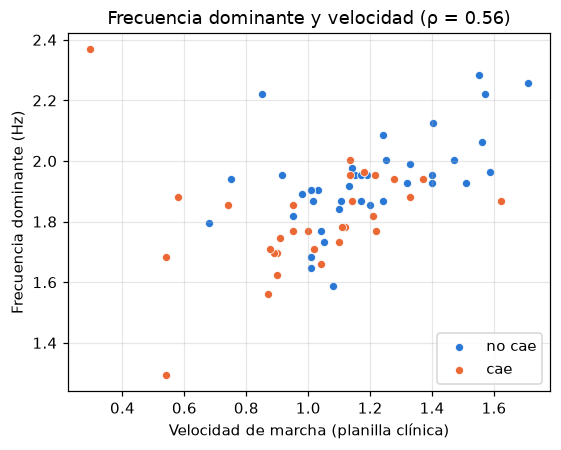

In [7]:
previos = pd.read_csv(RESULTADOS / "metricas_por_particion.csv")
previos["particion"] = previos.groupby("modelo").cumcount() + 1
ref_eda = next(m for m in previos["modelo"].unique() if m.startswith("Solo ") and m != "Solo TUG")
var_eda = ref_eda.replace("Solo ", "")
lab_X = pd.read_csv(PROCESADOS / "labwalks_modelo.csv")
control = evaluar(ref_eda, logistica(), lab_X[[var_eda]], y)
dif = np.abs(control["auc"].to_numpy() - previos[previos["modelo"] == ref_eda]["auc"].to_numpy()).max()
print(f"Comprobación: diferencia máxima con el notebook 03 en '{ref_eda}': {dif:.2e} "
      f"({'mismas particiones' if dif < 1e-6 else 'ATENCIÓN: las particiones no coinciden'})")

vel = []
if "velocidad" in d:
    print(f"\nVelocidad disponible en {d['velocidad'].notna().sum()} de {len(d)} personas "
          "(las que faltan se completan con la mediana de entrenamiento, igual que el TUG en el notebook 03)")
    vel.append(evaluar("Solo velocidad", logistica(), d[["velocidad"]], y))
    vel.append(evaluar("Velocidad + frecuencia dominante", logistica(), d[["velocidad", "frec_dominante_hz"]], y))
    vel = pd.concat(vel, ignore_index=True)
    vel.to_csv(RESULTADOS / "revision_velocidad_por_particion.csv", index=False)
    print(resumen(vel).to_string(index=False))

    rho, p = stats.spearmanr(d["frec_dominante_hz"], d["velocidad"], nan_policy="omit")
    print(f"\nCorrelación de Spearman entre frecuencia dominante y velocidad: ρ = {rho:.2f} (p = {p:.3g})")
    fig, eje = plt.subplots(figsize=(5.2, 4.2))
    for g, c in [(0, "#2a78d6"), (1, "#eb6834")]:
        s = d[d["cae"] == g]
        eje.scatter(s["velocidad"], s["frec_dominante_hz"], color=c, s=28, label="no cae" if g == 0 else "cae",
                    edgecolor="white", linewidth=0.5)
    eje.set(xlabel="Velocidad de marcha (planilla clínica)", ylabel="Frecuencia dominante (Hz)",
            title=f"Frecuencia dominante y velocidad (ρ = {rho:.2f})")
    eje.legend()
    fig.tight_layout()
    fig.savefig(FIGURAS / "revision_frecuencia_velocidad.png", dpi=150)
else:
    print("No se encontró la columna de velocidad.")

In [8]:
# Comparaciones de a pares en las mismas 50 particiones (prueba t corregida + Holm)
nuevos_05 = pd.read_csv(RESULTADOS / "metricas_por_particion_1_4.csv")
SELECCIONADO = "1 variable de cámara elegida en cada partición"
todas = pd.concat([previos[["modelo", "particion", "auc"]],
                   nuevos_05[nuevos_05["fuente"] == "laboratorio"][["modelo", "particion", "auc"]]]
                  + ([vel[["modelo", "particion", "auc"]]] if len(vel) else []), ignore_index=True)
auc = todas.pivot_table(index="particion", columns="modelo", values="auc")
pares = [("Solo velocidad", ref_eda), ("Solo velocidad", SELECCIONADO), ("Solo velocidad", "Solo TUG"),
         ("Velocidad + frecuencia dominante", "Solo velocidad")]
filas = []
for a, b in pares:
    if a in auc and b in auc:
        dm, p = prueba_t_corregida(auc[a], auc[b])
        filas.append({"modelo A": a, "modelo B": b, "AUC A": auc[a].mean(), "AUC B": auc[b].mean(),
                      "diferencia": dm, "p": p})
comp_vel = pd.DataFrame(filas)
if len(comp_vel):
    comp_vel["p_holm"] = holm(comp_vel["p"])
    comp_vel.to_csv(RESULTADOS / "revision_comparacion_velocidad.csv", index=False)
comp_vel.round(3)

,modelo A,modelo B,AUC A,AUC B,diferencia,p,p_holm
0,Solo velocidad,Solo frec_dominante_hz,0.666,0.745,-0.079,0.280,1.0
1,Solo velocidad,1 variable de cámara elegida en cada partición,0.666,0.724,-0.058,0.492,1.0
2,Solo velocidad,Solo TUG,0.666,0.657,0.009,0.887,1.0
3,Velocidad + frecuencia dominante,Solo velocidad,0.719,0.666,0.053,0.293,1.0


## 7. Frecuencia dominante, velocidad y TUG en las mismas personas

En el notebook 03, al TUG le faltaban 4 personas y se completaron con la mediana. Aquí se comparan las tres variables **solo con las personas que tienen los tres datos**, sin completar nada.

In [9]:
cols = [c for c in ("frec_dominante_hz", "velocidad", "tug") if c in d]
mismas = d.dropna(subset=cols).reset_index(drop=True)
ym = mismas["cae"].astype(int).to_numpy()
print(f"Personas con {', '.join(cols)}: {len(mismas)} ({ym.sum()} caen, {(1 - ym).sum()} no caen)")
partes = [evaluar(f"Solo {c}", logistica(), mismas[[c]], ym) for c in cols]
mismas_res = pd.concat(partes, ignore_index=True)
mismas_res.to_csv(RESULTADOS / "revision_mismas_personas.csv", index=False)
r = resumen(mismas_res)
piv = mismas_res.pivot_table(index="particion", columns="modelo", values="auc")
r["p_vs_azar"] = [prueba_t_corregida(piv[m], 0.5)[1] for m in r["modelo"]]
r["p_holm_vs_azar"] = holm(r["p_vs_azar"])
print(r.round(3).to_string(index=False))
if "Solo tug" in piv and "Solo frec_dominante_hz" in piv:
    dm, p = prueba_t_corregida(piv["Solo frec_dominante_hz"], piv["Solo tug"])
    print(f"\nFrecuencia dominante vs TUG en las mismas personas: diferencia de AUC {dm:+.3f}, p = {p:.3f}")

Personas con frec_dominante_hz, velocidad, tug: 68 (30 caen, 38 no caen)
                modelo  pruebas   auc     auc_ic95  exactitud  sensibilidad  especificidad    f1  p_vs_azar  p_holm_vs_azar
Solo frec_dominante_hz       50 0.741 [0.60; 0.88]      0.702         0.547          0.825 0.605      0.002           0.005
        Solo velocidad       50 0.690 [0.55; 0.83]      0.639         0.470          0.774 0.527      0.010           0.010
              Solo tug       50 0.675 [0.56; 0.79]      0.639         0.387          0.840 0.469      0.003           0.007

Frecuencia dominante vs TUG en las mismas personas: diferencia de AUC +0.066, p = 0.407


## 8. ¿El modelo elegido supera al azar y al TUG?

La revisión observó que solo se comparó cada modelo con el mejor. Aquí se responde la pregunta clínica: ¿el modelo elegido es mejor que lanzar una moneda (AUC = 0,5) y que el TUG? Se usan las mismas 50 particiones y Holm sobre las cuatro comparaciones.

Además, se dejan separados dos números que el informe 1.4 podía confundir:

* **"1 variable de cámara elegida en cada partición"**: el procedimiento honesto. Su AUC es el que se informa como desempeño esperado.
* **"Solo frecuencia dominante" (notebook 03)**: la variable fija, elegida mirando a todas las personas. Es la que usa el modelo final guardado, pero su AUC está inflado por el sesgo de selección.

In [10]:
filas = []
for modelo in (SELECCIONADO, ref_eda):
    if modelo not in auc:
        continue
    dm, p = prueba_t_corregida(auc[modelo], 0.5)
    filas.append({"modelo": modelo, "comparado con": "azar (AUC 0,5)", "AUC": auc[modelo].mean(), "diferencia": dm, "p": p})
    if "Solo TUG" in auc:
        dm, p = prueba_t_corregida(auc[modelo], auc["Solo TUG"])
        filas.append({"modelo": modelo, "comparado con": f"Solo TUG (AUC {auc['Solo TUG'].mean():.2f})".replace(".", ","),
                      "AUC": auc[modelo].mean(), "diferencia": dm, "p": p})
vs = pd.DataFrame(filas)
vs["p_holm"] = holm(vs["p"])
vs["significativo"] = np.where(vs["p_holm"] < ALFA, "sí", "no")
vs.to_csv(RESULTADOS / "revision_vs_azar_y_tug.csv", index=False)
vs.round(3)

,modelo,comparado con,AUC,diferencia,p,p_holm,significativo
0,1 variable de cámara elegida en cada partición,"azar (AUC 0,5)",0.724,0.224,0.006,0.017,sí
1,1 variable de cámara elegida en cada partición,"Solo TUG (AUC 0,66)",0.724,0.066,0.431,0.467,no
2,Solo frec_dominante_hz,"azar (AUC 0,5)",0.745,0.245,0.001,0.002,sí
3,Solo frec_dominante_hz,"Solo TUG (AUC 0,66)",0.745,0.088,0.233,0.467,no


## 9. Umbral de tamizaje en Hz, matriz de confusión y calibración

El modelo final (`modelo_final.joblib`) es una regresión logística con una sola variable, así que el umbral de probabilidad equivale a un valor de esa variable. Para la frecuencia dominante: **bajo cierto número de Hz, la persona se marca como de riesgo**.

El umbral del notebook 05 se eligió con las 72 personas, así que su especificidad (0,47) es optimista. Aquí se estima de forma honesta: en cada partición, el umbral se elige **solo con las personas de entrenamiento** (con una validación interna) y se aplica a las de prueba.

In [11]:
info = json.loads((MODELOS / "info_modelo_final.json").read_text(encoding="utf-8"))
final = joblib.load(MODELOS / "modelo_final.joblib")
VAR = info["variables_en_orden"]
UMBRAL = info["umbral_tamizaje"]
completo_lab = lab_X[["registro"]].merge(completo.drop(columns="clave"), on="registro", how="left")
Xf = completo_lab[VAR]
print(f"Modelo final: {info['modelo']} | variables: {VAR} | umbral de probabilidad: {UMBRAL}")

if len(VAR) == 1:
    v = VAR[0]
    malla = pd.DataFrame({v: np.linspace(Xf[v].min() - 0.5 * Xf[v].std(), Xf[v].max() + 0.5 * Xf[v].std(), 4001)})
    prob = final.predict_proba(malla)[:, 1]
    cruce = malla[v].to_numpy()[np.argmin(np.abs(prob - UMBRAL))]
    signo = final[-1].coef_[0][0]
    regla = "bajo" if signo < 0 else "sobre"
    print(f"\nUmbral expresado en la variable: riesgo alto si {v} está {regla} {cruce:.3f}")
    if v == "frec_dominante_hz":
        print(f"  = {cruce:.2f} Hz, unos {cruce * 60:.0f} pasos por minuto (la frecuencia dominante vertical "
              "corresponde aproximadamente al ritmo de los pasos)")
    medias = completo_lab.assign(cae=y).groupby("cae")[v].mean()
    print(f"  Como referencia: media en quienes no caen {medias.get(0, np.nan):.3f}, en quienes caen {medias.get(1, np.nan):.3f}")

Modelo final: 1 variable de cámara elegida en cada partición | variables: ['frec_dominante_hz'] | umbral de probabilidad: 0.3995

Umbral expresado en la variable: riesgo alto si frec_dominante_hz está bajo 1.927
  = 1.93 Hz, unos 116 pasos por minuto (la frecuencia dominante vertical corresponde aproximadamente al ritmo de los pasos)
  Como referencia: media en quienes no caen 1.934, en quienes caen 1.806


In [12]:
def umbral_por_sensibilidad(y_ent, p_ent, objetivo=SENSIBILIDAD_OBJETIVO):
    fpr, tpr, u = roc_curve(y_ent, p_ent)
    return u[np.argmax(tpr >= objetivo)]


honesto, fijo, todas_prob = [], [], []
matrices_honestas, matrices_fijas = [], []
for rep in range(N_REPETICIONES):
    cv = StratifiedKFold(n_splits=N_PARTICIONES, shuffle=True, random_state=SEMILLA + rep)
    pred_h, prob_rep = np.zeros(len(y), dtype=int), np.zeros(len(y))
    for ent, pru in cv.split(Xf, y):
        m = clone(final).fit(Xf.iloc[ent], y[ent])
        # umbral elegido solo con las personas de entrenamiento (validación interna de 5 partes)
        interna = StratifiedKFold(n_splits=N_PARTICIONES, shuffle=True, random_state=SEMILLA)
        p_int = cross_val_predict(clone(final), Xf.iloc[ent], y[ent], cv=interna, method="predict_proba")[:, 1]
        u = umbral_por_sensibilidad(y[ent], p_int)
        p_pru = m.predict_proba(Xf.iloc[pru])[:, 1]
        prob_rep[pru] = p_pru
        pred_h[pru] = (p_pru >= u).astype(int)
    pred_f = (prob_rep >= UMBRAL).astype(int)
    for nombre, pred, lista, mats in [("honesto", pred_h, honesto, matrices_honestas), ("fijo", pred_f, fijo, matrices_fijas)]:
        lista.append({"sensibilidad": recall_score(y, pred), "especificidad": recall_score(y, pred, pos_label=0)})
        mats.append(confusion_matrix(y, pred, labels=[0, 1]))
    todas_prob.append(prob_rep)

h, f = pd.DataFrame(honesto), pd.DataFrame(fijo)
print(f"Umbral fijo del notebook 05 ({UMBRAL:.3f}, elegido con todos): sensibilidad {f['sensibilidad'].mean():.2f}, "
      f"especificidad {f['especificidad'].mean():.2f}")
print(f"Umbral elegido solo con entrenamiento (honesto):     sensibilidad {h['sensibilidad'].mean():.2f} ± "
      f"{h['sensibilidad'].std():.2f}, especificidad {h['especificidad'].mean():.2f} ± {h['especificidad'].std():.2f}")

mat = np.mean(matrices_honestas, axis=0)
tabla_conf = pd.DataFrame(mat.round(1), index=["real: no cae", "real: cae"], columns=["predicho: bajo riesgo", "predicho: riesgo"])
print(f"\nMatriz de confusión con el umbral honesto (promedio de 10 repeticiones, {len(y)} personas):")
print(tabla_conf.to_string())

Umbral fijo del notebook 05 (0.400, elegido con todos): sensibilidad 0.81, especificidad 0.48
Umbral elegido solo con entrenamiento (honesto):     sensibilidad 0.78 ± 0.04, especificidad 0.54 ± 0.04

Matriz de confusión con el umbral honesto (promedio de 10 repeticiones, 72 personas):
              predicho: bajo riesgo  predicho: riesgo
real: no cae                   20.5              17.5
real: cae                       7.4              26.6


Puntaje de Brier: 0.216 (un modelo que siempre dice la proporción de caedores, 0.47, da 0.249; menor es mejor)


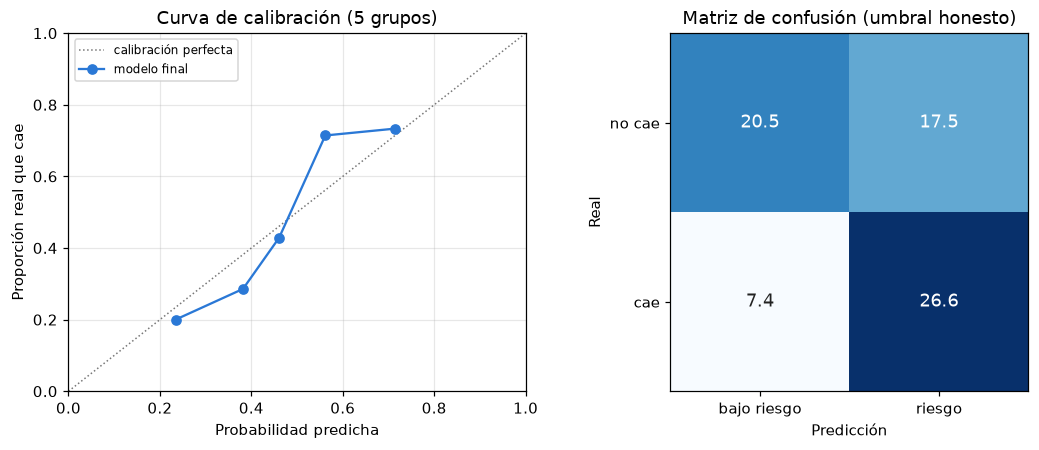

In [13]:
prob_media = np.mean(todas_prob, axis=0)
brier = np.mean([brier_score_loss(y, p) for p in todas_prob])
brier_ref = brier_score_loss(y, np.full(len(y), y.mean()))
print(f"Puntaje de Brier: {brier:.3f} (un modelo que siempre dice la proporción de caedores, {y.mean():.2f}, da {brier_ref:.3f}; "
      "menor es mejor)")

fig, ejes = plt.subplots(1, 2, figsize=(10, 4.2))
frac, pred_m = calibration_curve(y, prob_media, n_bins=5, strategy="quantile")
ejes[0].plot([0, 1], [0, 1], ":", color="#777777", lw=1, label="calibración perfecta")
ejes[0].plot(pred_m, frac, "o-", color="#2a78d6", label="modelo final")
ejes[0].set(xlabel="Probabilidad predicha", ylabel="Proporción real que cae", xlim=(0, 1), ylim=(0, 1),
            title="Curva de calibración (5 grupos)")
ejes[0].legend(fontsize=8)
im = ejes[1].imshow(mat, cmap="Blues")
for (i, j), val in np.ndenumerate(mat):
    ejes[1].text(j, i, f"{val:.1f}", ha="center", va="center", fontsize=12, color="white" if val > mat.max() / 2 else "#222222")
ejes[1].set_xticks([0, 1], ["bajo riesgo", "riesgo"])
ejes[1].set_yticks([0, 1], ["no cae", "cae"])
ejes[1].set(xlabel="Predicción", ylabel="Real", title="Matriz de confusión (umbral honesto)")
ejes[1].grid(False)
fig.tight_layout()
fig.savefig(FIGURAS / "revision_calibracion_confusion.png", dpi=150)
pd.DataFrame({"brier": [brier], "brier_referencia": [brier_ref],
              "sensibilidad_honesta": [h["sensibilidad"].mean()], "especificidad_honesta": [h["especificidad"].mean()],
              "sensibilidad_umbral_fijo": [f["sensibilidad"].mean()], "especificidad_umbral_fijo": [f["especificidad"].mean()]}
             ).to_csv(RESULTADOS / "revision_umbral_calibracion.csv", index=False)

## 10. Resumen para responder la revisión

In [14]:
fmt = lambda x, k=2: f"{x:.{k}f}".replace(".", ",")
print(f"* requirements.txt escrito con {len(lineas)} paquetes y versiones exactas.")
if "caidas_6m" in d:
    print(f"* Columna '6 Months Fall': {'posiblemente prospectiva' if ES_PROSPECTIVA else 'parece retrospectiva'} "
          f"según la regla del plan (ver sección 5).")
if len(vel):
    rv = resumen(vel).set_index("modelo")
    print(f"* Solo velocidad: AUC {fmt(rv.loc['Solo velocidad', 'auc'])} (IC 95 % {rv.loc['Solo velocidad', 'auc_ic95'].replace('.', ',')}); "
          f"velocidad + frecuencia dominante: {fmt(rv.loc['Velocidad + frecuencia dominante', 'auc'])}. "
          f"Correlación con la frecuencia dominante: ρ = {fmt(rho)}.")
for _, r in vs.iterrows():
    print(f"* {r['modelo']} vs {r['comparado con']}: diferencia {fmt(r['diferencia'])}, p Holm = {fmt(r['p_holm'], 3)} "
          f"({'significativa' if r['significativo'] == 'sí' else 'no significativa'}).")
if len(VAR) == 1:
    print(f"* Umbral del modelo final: riesgo si {VAR[0]} {regla} {fmt(cruce)}.")
print(f"* Con el umbral elegido sin mirar la prueba: sensibilidad {fmt(h['sensibilidad'].mean())}, "
      f"especificidad {fmt(h['especificidad'].mean())} (con el umbral del notebook 05: {fmt(f['especificidad'].mean())}).")
print(f"* Puntaje de Brier {fmt(brier, 3)} (referencia sin modelo {fmt(brier_ref, 3)}).")

* requirements.txt escrito con 13 paquetes y versiones exactas.
* Columna '6 Months Fall': posiblemente prospectiva según la regla del plan (ver sección 5).
* Solo velocidad: AUC 0,67 (IC 95 % [0,50; 0,83]); velocidad + frecuencia dominante: 0,72. Correlación con la frecuencia dominante: ρ = 0,56.
* 1 variable de cámara elegida en cada partición vs azar (AUC 0,5): diferencia 0,22, p Holm = 0,017 (significativa).
* 1 variable de cámara elegida en cada partición vs Solo TUG (AUC 0,66): diferencia 0,07, p Holm = 0,467 (no significativa).
* Solo frec_dominante_hz vs azar (AUC 0,5): diferencia 0,25, p Holm = 0,002 (significativa).
* Solo frec_dominante_hz vs Solo TUG (AUC 0,66): diferencia 0,09, p Holm = 0,467 (no significativa).
* Umbral del modelo final: riesgo si frec_dominante_hz bajo 1,93.
* Con el umbral elegido sin mirar la prueba: sensibilidad 0,78, especificidad 0,54 (con el umbral del notebook 05: 0,48).
* Puntaje de Brier 0,216 (referencia sin modelo 0,249).


**Interpretación**
La regla del plan concluyó “posiblemente prospectiva”, pero era demasiado estricta: la columna “6 Months Fall” se correlaciona ρ = 0,93 con las caídas del año anterior (que la predicen con AUC 0,98), y sus medias coinciden con las caídas de los 6 meses anteriores informadas por Weiss et al. Se concluye que es retrospectiva y no se usa como etiqueta nueva. La frecuencia dominante se correlaciona con la velocidad (ρ = 0,56) y agregarla a la velocidad no mejora significativamente; su aporte propio no se puede separar con 72 personas. El modelo elegido supera al azar, pero no al TUG. Con el umbral elegido sin mirar la prueba, la especificidad es 0,54.

**Referencia:** A. Weiss *et al.*, "Does the evaluation of gait quality during daily life provide insight into fall risk?", *Neurorehabil. Neural Repair*, vol. 27, no. 8, pp. 742–752, 2013.